# Lab 0 · Python and data preparation
**Course:** AI in Oil & Gas · Part I, AI & ML Fundamentals  ·  **Time:** 60 min  ·  **Slides:** Modules 04 and 08

Before any algorithm, look at the data. In this lab you load the three course datasets, find what is wrong with
them, and prepare them so a model can learn.

| Dataset | File | Task | Rows | Inputs → target |
|---|---|---|---|---|
| Asphaltene precipitation | `asphaltene.csv` | regression | 167 | temperature, n-alkane carbon number, dilution ratio → wt% precipitated |
| EOR screening | `eor_screening.csv` | classification | 455 | permeability, depth, API, viscosity, temperature, oil saturation → EOR method |
| Virtual flow metering | `vfm_well_rates.csv` | regression | 2,100 | choke, BHP, WHP, WHT, Psep, Tsep → oil, water, gas rates |

**You will:** load and describe data · plot distributions · detect outliers with the IQR rule · transform skewed inputs · scale · split.

In [1]:
# --- setup: works locally and in Google Colab ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("aiml"):
    print("Upload the course kit zip to Colab, then unzip it:  !unzip -q aiml_course_kit.zip && %cd aiml_course_kit")
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data" if os.path.exists("../data") else "data"

from aiml.data import load_asphaltene, load_eor, load_vfm, ASPH_FEATURES, ASPH_TARGET, EOR_FEATURES
from aiml.prep import detect_outliers_iqr, outlier_table, plot_outliers
asph = pd.read_csv(f"{DATA}/asphaltene.csv")
eor = pd.read_csv(f"{DATA}/eor_screening.csv")
vfm = pd.read_csv(f"{DATA}/vfm_well_rates.csv")
asph.head()

,temperature_K,alkane_carbon_number,dilution_ratio,asphaltene_wt_pct
0,293,10,2.63773,0.611815
1,293,10,5.04174,2.401060
2,293,10,9.64942,3.583400
3,293,10,14.35730,4.258230
4,293,10,20.63440,4.751910


## 1 · First look
`info()` shows types and missing values; `describe()` the ranges. Read them like an engineer: are the units and ranges physical?

In [2]:
asph.info(); asph.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   temperature_K         167 non-null    int64  
 1   alkane_carbon_number  167 non-null    int64  
 2   dilution_ratio        167 non-null    float64
 3   asphaltene_wt_pct     167 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 5.3 KB


,count,mean,std,min,25%,50%,75%,max
temperature_K,167.0,312.023952,14.839280,293.000000,293.00000,308.00000,323.000000,332.0000
alkane_carbon_number,167.0,8.119760,2.235536,5.000000,6.00000,8.00000,10.000000,12.0000
dilution_ratio,167.0,12.572310,7.787710,2.203670,5.01094,9.75042,20.579600,24.4741
asphaltene_wt_pct,167.0,5.481997,8.285514,0.166916,1.90438,3.45686,4.883125,42.1751


In [3]:
eor.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
project_id,455.0,103.1,68.3,1.0,44.0,96.0,158.5,246.0
permeability_md,455.0,1360.6,1939.3,0.0,30.0,500.0,2000.0,11500.0
depth_ft,455.0,3799.4,2972.1,33.0,1400.0,3000.0,5400.0,18500.0
api_gravity,455.0,25.8,12.0,8.0,13.0,27.0,37.0,57.0
viscosity_cp,455.0,15363.6,234511.6,0.0,1.0,10.0,1976.0,4990000.0
temperature_F,455.0,121.3,43.1,5.0,100.0,106.0,133.0,325.0
oil_saturation_pct,455.0,60.6,15.9,1.0,50.0,60.0,70.0,98.0


### ✏️ Your turn 1
In `eor`, find (a) how many projects report a viscosity of **0 cP**, (b) the lowest reservoir temperature, and
(c) how many rows are exact duplicates in the six inputs and the label. Which of these are data errors?

In [4]:
print("viscosity = 0 cP:", (eor.viscosity_cp == 0).sum(), "projects (a rounded value; real oil is never 0 cP)")
print("lowest temperature:", eor.temperature_F.min(), "°F (a 5 °F reservoir is not physical: likely a typing error)")
print("duplicates:", eor.duplicated(subset=EOR_FEATURES + ["eor_method"]).sum(), "rows (same field reported twice?)")

viscosity = 0 cP: 45 projects (a rounded value; real oil is never 0 cP)
lowest temperature: 5.0 °F (a 5 °F reservoir is not physical: likely a typing error)
duplicates: 43 rows (same field reported twice?)


## 2 · Distributions
Skewed inputs (viscosity, permeability) span several orders of magnitude: a model sees almost all points squeezed near zero.

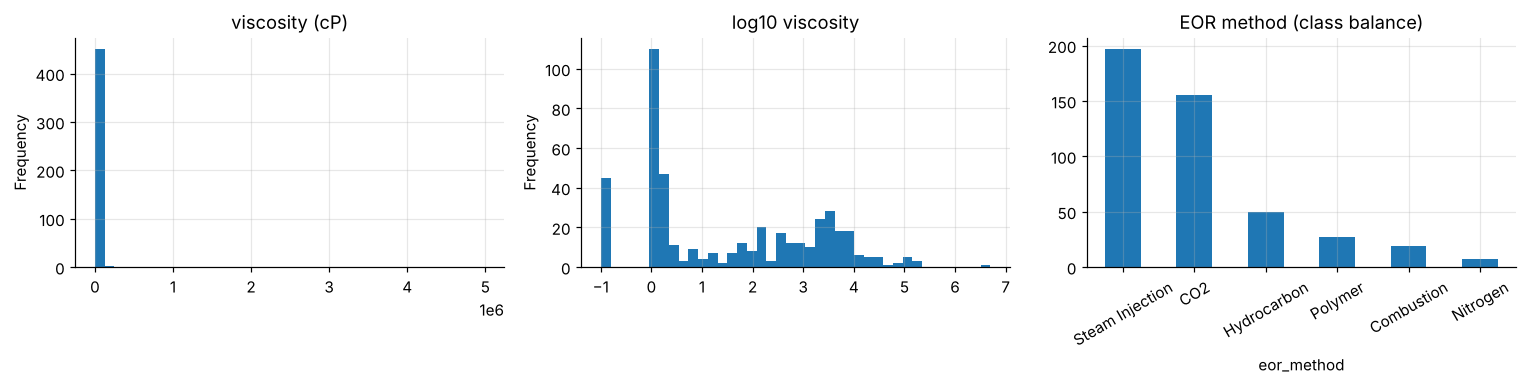

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
eor.viscosity_cp.plot.hist(bins=40, ax=ax[0], title="viscosity (cP)")
np.log10(eor.viscosity_cp.clip(lower=0.1)).plot.hist(bins=40, ax=ax[1], title="log10 viscosity")
eor.eor_method.value_counts().plot.bar(ax=ax[2], title="EOR method (class balance)", rot=30)
plt.tight_layout(); plt.show()

## 3 · Outliers with the IQR rule
The course function `detect_outliers_iqr` flags values outside Q1 − 1.5·IQR and Q3 + 1.5·IQR.

In [6]:
outlier_table(asph)

,column,lower,upper,n_outliers,share_%
0,temperature_K,248.000,368.000,0,0.0
1,alkane_carbon_number,0.000,16.000,0,0.0
2,dilution_ratio,-18.342,43.933,0,0.0
3,asphaltene_wt_pct,-2.564,9.351,15,9.0


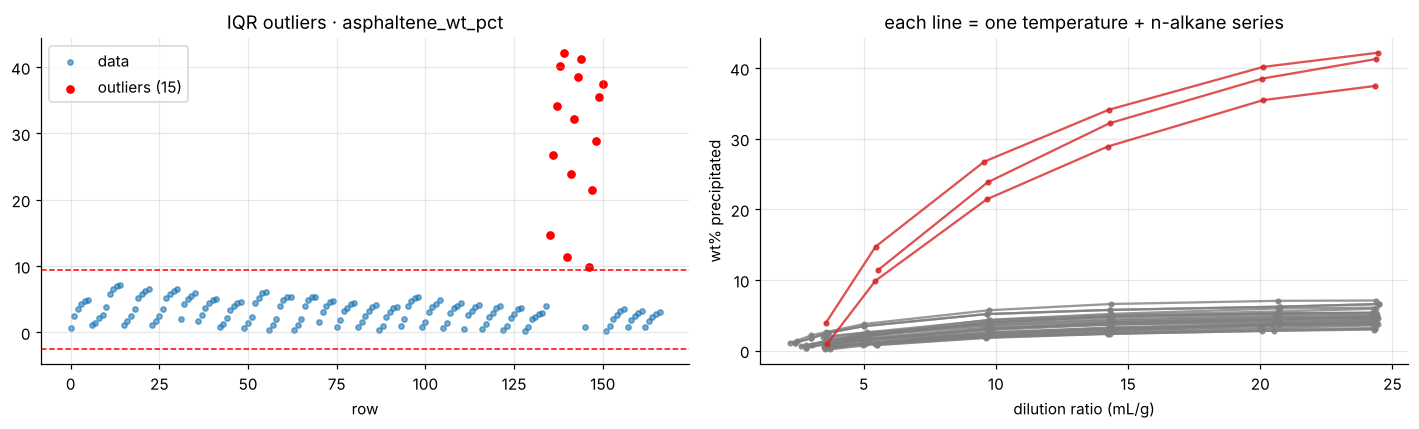

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_outliers(asph, ASPH_TARGET, ax=ax[0])
for (T, C), g in asph.groupby(["temperature_K", "alkane_carbon_number"]):
    ax[1].plot(g.dilution_ratio, g[ASPH_TARGET], "o-", ms=3, alpha=.8, color="tab:red" if T == 332 and C <= 8 else "tab:grey")
ax[1].set_xlabel("dilution ratio (mL/g)"); ax[1].set_ylabel("wt% precipitated"); ax[1].set_title("each line = one temperature + n-alkane series")
plt.tight_layout(); plt.show()

The IQR rule flags 15 values. Plotted by series (right), they are not random spikes: they belong to **three complete
series** of 17 tests (332 K with n-C6, C7, C8) that are about ten times higher than every other series, while 332 K with C9–C12 looks normal. A statistical rule finds
them; only engineering judgement can decide whether they are a different unit, a different oil or a real effect.

`load_asphaltene()` keeps them and adds a `suspect` column so you can model with and without them (Lab 1).

### ✏️ Your turn 2
Run `detect_outliers_iqr` on every numeric column of `vfm`. Are any of the flagged values *errors*? (Hint: look at the
water rates and remember that water cut goes from 0 to 0.8 in the tests.)

In [8]:
print(outlier_table(vfm))
print("\nNo column has IQR outliers: wide ranges by design (10 chokes, water cut 0-0.8), not errors.")

             column     lower     upper  n_outliers  share_%
0          choke_in    -1.200     3.120           0      0.0
1           bhp_psi  3086.105  6365.265           0      0.0
2           whp_psi  -930.655  4737.545           0      0.0
3             wht_F    57.205   235.805           0      0.0
4          psep_psi  -250.000   950.000           0      0.0
5            tsep_F     4.110   186.350           0      0.0
6    oil_rate_stb_d -2677.400  7408.200           0      0.0
7  water_rate_bbl_d -3434.100  6668.300           0      0.0
8  gas_rate_mmscf_d   -10.527    28.612           0      0.0

No column has IQR outliers: wide ranges by design (10 chokes, water cut 0-0.8), not errors.


## 4 · A hidden problem: duplicated tests
The VFM file looks large (2,100 rows). How many *different* well tests does it hold?

In [9]:
phys = ["choke_in", "bhp_psi", "whp_psi", "wht_F", "tsep_F", "oil_rate_stb_d", "water_rate_bbl_d", "gas_rate_mmscf_d"]
print("rows:", len(vfm), " different physical tests:", len(vfm[phys].drop_duplicates()))
vfm[(vfm.bhp_psi == 5410.33)][["choke_in", "bhp_psi", "whp_psi", "psep_psi", "oil_rate_stb_d"]]

rows: 2100  different physical tests: 976


,choke_in,bhp_psi,whp_psi,psep_psi,oil_rate_stb_d
0,0.25,5410.33,3185.75,100,954.6
5,0.25,5410.33,3185.75,200,954.6
10,0.25,5410.33,3185.75,300,954.6
15,0.25,5410.33,3185.75,400,954.6
20,0.25,5410.33,3185.75,500,954.6
25,0.25,5410.33,3185.75,600,954.6


The same well test is repeated for each separator pressure (100–600 psi), and the rates do not change. With a random
train/test split the "test" rows are copies of training rows, so any model looks perfect. `load_vfm()` adds a `case_id`;
always split by it (Lab 3).

## 5 · Scaling and splitting
Fit the scaler on the **training** rows only, then apply it to the test rows.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
X, y = asph[ASPH_FEATURES], asph[ASPH_TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler().fit(X_train)
print(pd.DataFrame(sc.transform(X_train), columns=ASPH_FEATURES).describe().loc[["mean", "std"]].round(3))
mm = MinMaxScaler().fit(X_train); print(pd.DataFrame(mm.transform(X_test), columns=ASPH_FEATURES).describe().loc[["min", "max"]].round(3))

      temperature_K  alkane_carbon_number  dilution_ratio
mean          0.000                 0.000           0.000
std           1.004                 1.004           1.004
     temperature_K  alkane_carbon_number  dilution_ratio
min            0.0                   0.0           0.009
max            1.0                   1.0           1.000


### ✏️ Your turn 3
For the EOR data, make a **stratified** 80/20 split (`stratify=y`) and print the class counts of the test set.
Why is stratification important here? (Hint: how many Nitrogen projects are there?)

In [11]:
y = eor.eor_method
X_train, X_test, y_train, y_test = train_test_split(eor[EOR_FEATURES], y, test_size=0.2, random_state=42, stratify=y)
print(y_test.value_counts())
print("Only 7 Nitrogen projects in total: without stratify a test set can easily get 0 or 4 of them.")

eor_method
Steam Injection    40
CO2                31
Hydrocarbon        10
Polymer             5
Combustion          4
Nitrogen            1
Name: count, dtype: int64
Only 7 Nitrogen projects in total: without stratify a test set can easily get 0 or 4 of them.


## Key ideas
* Read `describe()` like an engineer: a 0 cP oil or a 5 °F reservoir is a data error, not a feature.
* The IQR rule finds unusual values; deciding whether they are wrong needs domain knowledge.
* Duplicated rows make random splits leak: split by the physical case.
* Log-transform inputs that span orders of magnitude; scale using training data only; stratify small classes.